# Fraud Detection: Feature Selection

Milestone 3. The error analysis in [10_error-analysis.ipynb](10_error-analysis.ipynb) showed where the tuned LightGBM is weak:
- it mainly finds fraud with **high consumption** and misses fraud that hides consumption,
- the **sum features grow with the number of bills**, so long histories look risky,
- it ranks **long-history** and **young** clients worst.

Here we test new features that target these weak spots, and we test whether some current features can be removed.

**Method:**
- **The model stays fixed**: the tuned LightGBM settings from [09_hyperparameter-tuning.ipynb](09_hyperparameter-tuning.ipynb) (`models/lightgbm_best_params.json`). Any change in the score comes from the features only.
- **The same 5 stratified folds** on the training split as in notebooks 08 and 09, scored with **ROC-AUC** (main metric), PR-AUC next to it.
- **Whole groups** of features are tested, not single columns (single columns change the score too little to measure).
- **Adding:** current features + one new group. **Removing:** current features − one current group.
- Because every set uses the same folds, we compare **fold by fold** (paired comparison).

**Decision rule** (set before looking at the results):
- a new group is **kept** if the mean CV ROC-AUC improves by **more than 0.002** and it is better in **at least 4 of 5 folds**,
- a current group is **removed** if the mean CV ROC-AUC drops by **no more than 0.001** (simpler is better when the score is the same).

The final feature set is checked **once** on the validation split against the current model.

Note: groups A (per-bill levels) and B (time features) reopen two team decisions from 2026-10-20 (see [protocol.md](protocol.md)). The results here are the input for the team to decide.

The notebook shows tables and one chart: the confusion matrices of the current and the new feature set.

In [1]:
# reload features.py when it changes, so a running kernel does not use an old version
%load_ext autoreload
%autoreload 2

# libraries for data handling, the model, cross-validation and the metrics
import json
import numpy as np
import pandas as pd
from pathlib import Path
from lightgbm import LGBMClassifier
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate

from features import build_extra_features

pd.set_option("display.max_columns", 40)
FEATURE_DIR = Path("data/features")
CLEAN_DIR = Path("data/clean")
MODEL_DIR = Path("models")
RANDOM_STATE = 42

## 1. Build the new features

`build_extra_features()` in [features.py](features.py) works like `build_features()`: every value comes from the client's own bills, nothing is learned from other clients, so the same function is used for train, validation and test.

We build the new columns from the cleaned tables and join them to the existing feature tables from notebook 06. The existing tables keep the 80/20 train/validation split.

In [2]:
# read one feature table from data/features, with client_id as the index
def load(name):
    return pd.read_csv(FEATURE_DIR / f"{name}.csv", index_col="client_id")

X_train, X_valid, X_test = load("X_train"), load("X_valid"), load("X_test")
y_train, y_valid = load("y_train")["target"], load("y_valid")["target"]

# cleaned client and invoice tables (the input of the feature engineering)
client_train = pd.read_csv(CLEAN_DIR / "client_train_clean.csv", parse_dates=["creation_date"])
invoice_train = pd.read_csv(CLEAN_DIR / "invoice_train_clean.csv", parse_dates=["invoice_date"], low_memory=False)
client_test = pd.read_csv(CLEAN_DIR / "client_test_clean.csv", parse_dates=["creation_date"])
invoice_test = pd.read_csv(CLEAN_DIR / "invoice_test_clean.csv", parse_dates=["invoice_date"], low_memory=False)

# new columns for all Zindi train clients (train and validation) and for the test clients
extra_train = build_extra_features(client_train, invoice_train)
extra_test = build_extra_features(client_test, invoice_test)

# join the new columns to the existing tables, client by client
X_train_v2 = X_train.join(extra_train)
X_valid_v2 = X_valid.join(extra_train)
X_test_v2 = X_test.join(extra_test)

print(X_train_v2.shape, X_valid_v2.shape, X_test_v2.shape)

(108394, 41) (27099, 41) (58069, 41)


In [3]:
# definition-of-done checks, as in notebook 06
for name, new, old in [("train", X_train_v2, X_train), ("valid", X_valid_v2, X_valid), ("test", X_test_v2, X_test)]:
    assert new.index.equals(old.index), f"{name}: clients changed"
    assert new[extra_train.columns].notna().any().all(), f"{name}: a new column is empty"
assert list(X_train_v2.columns) == list(X_valid_v2.columns) == list(X_test_v2.columns)
assert not {"client_id", "target"} & set(X_train_v2.columns)

# save the extended tables for the next notebooks (data/ is not committed)
for name, table in {"X_train_v2": X_train_v2, "X_valid_v2": X_valid_v2, "X_test_v2": X_test_v2}.items():
    table.to_csv(FEATURE_DIR / f"{name}.csv")
print("All checks passed, tables saved.")

All checks passed, tables saved.


### The new columns

| Group | Column | How (per client) | Why (finding in notebook 10) |
|---|---|---|---|
| **A. Per-bill levels** | `consommation_level_k_per_bill` (k = 1 to 4) | level-k sum / number of bills | the sums grow with the history length |
| **B. Time** | `client_age_years` | years from `creation_date` to 2020-01-01 | young clients are missed more often |
| | `history_years` | years from the first to the last bill | long histories are ranked worst |
| | `bills_per_year` | number of bills / history years | |
| | `gap_mean_days`, `gap_max_days` | days between distinct bill dates | long breaks in the bills |
| | `months_number_mean`, `months_number_max` | months billed per bill | kept as a raw column since the cleaning |
| **C. Change over time** | `recent_vs_early` | mean consumption in the last 2 years / mean before | missed fraud hides consumption |
| | `max_drop` | biggest decrease between two bills of one meter | |
| | `zero_share` | share of bills with consumption 0 | |
| **D. Meter** | `n_counters` | number of different meters | a meter swap can be a sign of tampering |
| | `statue_unusual_share` | share of bills with an unusual meter status | |
| | `coef_not1_share` | share of bills with a counter coefficient other than 1 | |

Missing values (left as NaN, LightGBM handles them):

In [4]:
# share of clients without a value, per new column (training split)
missing = X_train_v2[extra_train.columns].isna().mean().mul(100).round(1)
missing[missing > 0].rename("missing (%)")

gap_mean_days       3.9
gap_max_days        3.9
recent_vs_early    17.7
Name: missing (%), dtype: float64

## 2. Feature groups and the test helper

In [5]:
levels = [f"consommation_level_{k}" for k in range(1, 5)]

# the current 24 features in groups
current_groups = {
    "basic statistics": ["n_bills", "cons_mean", "cons_median", "cons_std", "cons_min", "cons_max"],
    "level sums": [f"{l}_sum" for l in levels],
    "level max": [f"{l}_max" for l in levels],
    "backward index": ["backward_count", "has_backward"],
    "max change": ["max_change"],
    "per meter": ["cons_std_elec", "max_change_elec", "cons_std_gaz", "max_change_gaz"],
    "categories": ["tarif_type", "client_catg", "region"],
}
# the new groups
new_groups = {
    "A. per-bill levels": [f"{l}_per_bill" for l in levels],
    "B. time": ["client_age_years", "history_years", "bills_per_year", "gap_mean_days", "gap_max_days",
                "months_number_mean", "months_number_max"],
    "C. change over time": ["recent_vs_early", "max_drop", "zero_share"],
    "D. meter": ["n_counters", "statue_unusual_share", "coef_not1_share"],
}
# current groups we test for removal (low importance in notebook 08/11, or doubled information)
removal_candidates = {
    "per meter": current_groups["per meter"],
    "level max": current_groups["level max"],
    "cons_min and cons_median": ["cons_min", "cons_median"],
}

reference = [c for group in current_groups.values() for c in group]
assert sorted(reference) == sorted(X_train.columns), "the groups must cover the 24 current features"
assert sorted(c for g in new_groups.values() for c in g) == sorted(extra_train.columns)
print(len(reference), "current features,", sum(len(g) for g in new_groups.values()), "new features")

24 current features, 17 new features


In [6]:
# the tuned LightGBM settings from notebook 09 (class weight "balanced" included)
best_params = json.loads((MODEL_DIR / "lightgbm_best_params.json").read_text())
print(best_params)

# the same 5 stratified folds as in notebooks 08 and 09
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_scores(columns):
    # cross-validate the fixed tuned model on the given columns; returns the score of every fold
    model = LGBMClassifier(**best_params, n_jobs=-1, verbose=-1)
    result = cross_validate(model, X_train_v2[columns], y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    return result["test_roc_auc"], result["test_average_precision"]


def compare(name, columns, ref_auc):
    # one table row: mean scores and the paired comparison with the reference, fold by fold
    auc, pr = cv_scores(columns)
    return {
        "test": name,
        "features": len(columns),
        "CV ROC-AUC": auc.mean(),
        "change": auc.mean() - ref_auc.mean(),
        "folds better": int((auc > ref_auc).sum()),
        "CV PR-AUC": pr.mean(),
    }

{'colsample_bytree': 0.8676080596203861, 'learning_rate': 0.039270026903279916, 'max_depth': 6, 'min_child_samples': 118, 'n_estimators': 362, 'num_leaves': 30, 'reg_lambda': 1.857328833311487, 'subsample': 0.822080324639785, 'class_weight': 'balanced', 'subsample_freq': 1, 'random_state': 42}


## 3. Reference: the current 24 features

This must match the best CV score of notebook 09 (0.7687), because the model, the settings and the folds are the same.

In [7]:
ref_auc, ref_pr = cv_scores(reference)
print(f"reference CV ROC-AUC: {ref_auc.mean():.4f} (± {ref_auc.std():.4f}), CV PR-AUC: {ref_pr.mean():.4f}")
print("per fold:", ref_auc.round(4))

reference CV ROC-AUC: 0.7687 (± 0.0044), CV PR-AUC: 0.1747
per fold: [0.7723 0.7607 0.7723 0.7673 0.771 ]


## 4. Adding new groups (one at a time)

In [8]:
add_rows = [compare(f"+ {name}", reference + cols, ref_auc) for name, cols in new_groups.items()]
add_table = pd.DataFrame(add_rows).set_index("test")

# decision rule: keep if the mean improves by more than 0.002 and at least 4 of 5 folds are better
add_table["keep"] = (add_table["change"] > 0.002) & (add_table["folds better"] >= 4)
add_table.round(4)

,features,CV ROC-AUC,change,folds better,CV PR-AUC,keep
test,,,,,,
+ A. per-bill levels,28,0.7687,-0.0001,3,0.1743,False
+ B. time,31,0.7878,0.0191,5,0.1929,True
+ C. change over time,27,0.7693,0.0006,2,0.1763,False
+ D. meter,27,0.8358,0.0671,5,0.2859,True


## 5. Removing current groups (one at a time)

In [9]:
remove_rows = [compare(f"- {name}", [c for c in reference if c not in cols], ref_auc)
               for name, cols in removal_candidates.items()]
remove_table = pd.DataFrame(remove_rows).set_index("test")

# decision rule: remove if the mean drops by no more than 0.001
remove_table["remove"] = remove_table["change"] >= -0.001
remove_table.round(4)

,features,CV ROC-AUC,change,folds better,CV PR-AUC,remove
test,,,,,,
- per meter,20,0.7650,-0.0038,0,0.1711,False
- level max,20,0.7681,-0.0007,2,0.1729,True
- cons_min and cons_median,22,0.7649,-0.0038,0,0.1718,False


## 6. The combined feature set

Current features + all kept new groups − all removable groups. Groups can overlap in what they tell the model, so the combination is tested again.

In [10]:
kept = [name.removeprefix("+ ") for name in add_table.index[add_table["keep"]]]
removed = [name.removeprefix("- ") for name in remove_table.index[remove_table["remove"]]]
print("new groups kept:     ", kept or "none")
print("current groups removed:", removed or "none")

drop = {c for name in removed for c in removal_candidates[name]}
selected = [c for c in reference if c not in drop] + [c for name in kept for c in new_groups[name]]

combined = pd.DataFrame([compare("combined set", selected, ref_auc)]).set_index("test")
combined.round(4)

new groups kept:      ['B. time', 'D. meter']
current groups removed: ['level max']


,features,CV ROC-AUC,change,folds better,CV PR-AUC
test,,,,,
combined set,30,0.8476,0.0788,5,0.3048


### Final check on the validation split (used once)

Both models are fitted on the whole training split with the same settings, then scored on the validation clients.

In [11]:
def valid_proba(columns):
    # fit the fixed tuned model on all training clients, predict the validation clients
    model = LGBMClassifier(**best_params, n_jobs=-1, verbose=-1).fit(X_train_v2[columns], y_train)
    return model.predict_proba(X_valid_v2[columns])[:, 1]

proba = {"current features (24)": valid_proba(reference), f"new feature set ({len(selected)})": valid_proba(selected)}

valid_table = pd.DataFrame({
    name: {"valid ROC-AUC": roc_auc_score(y_valid, p), "valid PR-AUC": average_precision_score(y_valid, p)}
    for name, p in proba.items()
}).T
valid_table.round(4)

,valid ROC-AUC,valid PR-AUC
current features (24),0.7721,0.1812
new feature set (30),0.8585,0.3195


### Current vs new feature set: confusion matrices

As in notebook 10, each model flags the **10% of validation clients with its highest scores** (the STEG inspection scenario: 2,710 visits). Rows = the real class, columns = flagged or not.

,caught fraud,missed fraud,false alarms,fraud caught (recall),hit rate (precision)
current features (24),510.0,1003.0,2200.0,0.337,0.188
new feature set (30),775.0,738.0,1935.0,0.512,0.286


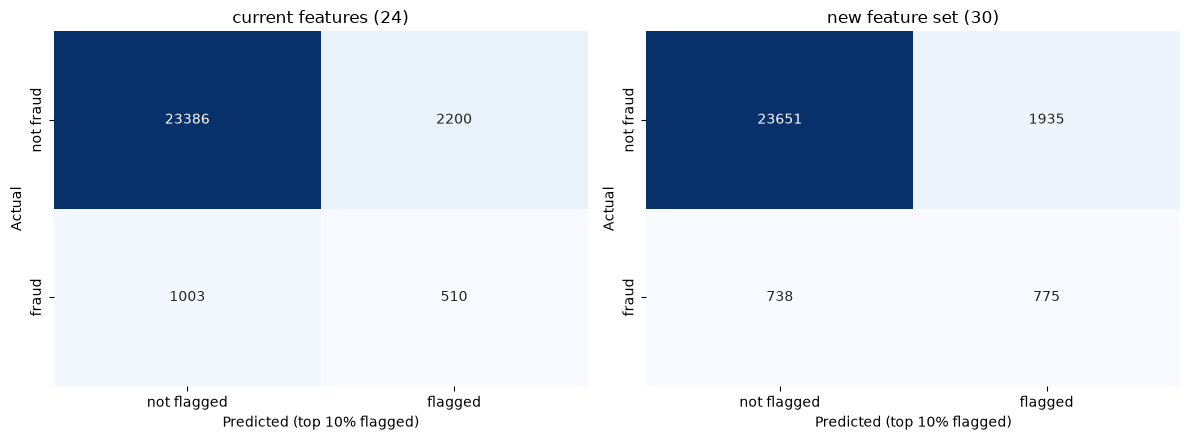

In [12]:
matrices, rows = {}, {}
for name, p in proba.items():
    # each model flags its own top 10% of validation clients
    flagged = (p >= np.quantile(p, 0.9)).astype(int)
    matrices[name] = confusion_matrix(y_valid, flagged)
    (tn, fp), (fn, tp) = matrices[name]
    rows[name] = {"caught fraud": tp, "missed fraud": fn, "false alarms": fp,
                  "fraud caught (recall)": tp / (tp + fn), "hit rate (precision)": tp / (tp + fp)}

display(pd.DataFrame(rows).T.round(3))

# both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, cm) in zip(axes, matrices.items()):
    sns.heatmap(cm, annot=True, fmt="g", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["not flagged", "flagged"], yticklabels=["not fraud", "fraud"])
    ax.set_xlabel("Predicted (top 10% flagged)")
    ax.set_ylabel("Actual")
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [13]:
# save the chosen columns, so the final notebook uses exactly this feature set
(MODEL_DIR / "selected_features.json").write_text(json.dumps(
    {"features": selected, "new groups kept": kept, "current groups removed": removed}, indent=2))
print(len(selected), "features saved to models/selected_features.json")

30 features saved to models/selected_features.json


## 7. Check: when does the newest meter start?

`n_counters` is the strongest new feature. Before we trust it, we check **when** the extra meters appear. If they appear late in a fraud client's history, STEG may have replaced the meter **after** it found the fraud. Then the feature partly shows fraud that was already detected (possible leakage). A meter replacement here means an extra meter of the **same type** (electricity or gas).

In [14]:
# extra meters within the same meter type = meter replacements
bills = invoice_train[["client_id", "invoice_date", "counter_number", "counter_type"]]
target = client_train.set_index("client_id")["target"]
per_meter = bills.groupby(["client_id", "counter_type"])["counter_number"].nunique() - 1
replacements = per_meter.groupby("client_id").sum()

# fraud rate by number of replacements (3 means 3 or more)
pd.DataFrame({"replacements": replacements.clip(upper=3), "target": target})     .groupby("replacements")["target"].agg(fraud_rate="mean", clients="size").round(3)

,fraud_rate,clients
replacements,,
0,0.028,107232
1,0.153,23814
2,0.203,3833
3,0.182,614


In [15]:
# first bill date of every meter, then the newest meter of each meter type
start = bills.groupby(["client_id", "counter_type", "counter_number"])["invoice_date"].min().reset_index()
newest = start.sort_values("invoice_date").groupby(["client_id", "counter_type"]).tail(1)
span = bills.groupby("client_id")["invoice_date"].agg(first="min", last="max")
newest = newest.join(span, on="client_id")

# only meter types that had a replacement
replaced = per_meter[per_meter > 0].index
newest = newest.set_index(["client_id", "counter_type"]).loc[lambda d: d.index.isin(replaced)].reset_index()

# position of the newest meter in the client's history: 0 = first bill, 1 = last bill
history_days = (newest["last"] - newest["first"]).dt.days.clip(lower=1)
newest["position in history"] = (newest["invoice_date"] - newest["first"]).dt.days / history_days
newest["years before last bill"] = (newest["last"] - newest["invoice_date"]).dt.days / 365.25
newest["client"] = newest["client_id"].map(target).map({0: "honest", 1: "fraud"})

# medians for fraud and honest clients
newest.groupby("client")[["position in history", "years before last bill"]].median().round(2)

,position in history,years before last bill
client,,
fraud,0.71,3.32
honest,0.35,6.01


**Reading:** for fraud clients the newest meter starts much later in their history than for honest clients. This fits the idea that meters are often replaced after fraud is found. The data has no detection date, so we cannot prove it. The team decided to use `n_counters` anyway (see [protocol.md](protocol.md)): it does not matter for the Zindi test set (same data period, same meter pattern), but it is a question for STEG and a point for the presentation.

## Result

| Test | Features | CV ROC-AUC | Change | Folds better | Decision |
|---|---|---|---|---|---|
| Reference (current) | 24 | 0.769 | | | |
| + A. per-bill levels | 28 | 0.769 | −0.000 | 3 of 5 | not kept |
| + **B. time** | 31 | 0.788 | **+0.019** | 5 of 5 | **kept** |
| + C. change over time | 27 | 0.769 | +0.001 | 2 of 5 | not kept |
| + **D. meter** | 27 | 0.836 | **+0.067** | 5 of 5 | **kept** |
| − per meter | 20 | 0.765 | −0.004 | 0 of 5 | stays |
| − **level max** | 20 | 0.768 | −0.001 | 2 of 5 | **removed** |
| − cons_min and cons_median | 22 | 0.765 | −0.004 | 0 of 5 | stay |
| **Combined set** | **30** | **0.848** | **+0.079** | 5 of 5 | |

**Validation check (used once):** ROC-AUC **0.859** with the combined set vs 0.772 with the current features. PR-AUC almost doubles (0.320 vs 0.181). The improvement is confirmed on unseen clients.

**In the inspection scenario** (top 10% of validation clients flagged, 2,710 visits), the new feature set catches **775 instead of 510 fraud cases** (51% instead of 34% of all fraud), and the hit rate of the visits rises from 19% to 29%. (The current set scores 0.772 here, slightly below 0.774 in notebook 09, because the columns are in a different order and LightGBM samples columns at random.)

**What helps:**
- **D. meter features**, almost entirely through `n_counters` (number of different meters). On its own it lifts CV ROC-AUC from 0.769 to 0.830. Clients whose meter was **replaced** (an extra meter of the same type) are fraud in 15% to 20% of cases, compared with 2.8% without a replacement.
- **B. time features**: +0.019, better in every fold. This confirms the error analysis (long-history and young clients were ranked worst).

**What does not help:**
- **A. per-bill levels:** the model already gets this from the sums and `n_bills`.
- **C. change over time:** no clear gain.
- The **4 level max columns** can go without losing anything.

**Important caveat about `n_counters` (possible leakage):**
For fraud clients, the newest meter starts late in their history: in the median case, 71% of the way through, about 3 years before their last bill. For honest clients it starts much earlier (35%, about 6 years before). One explanation is that STEG **replaces the meter after it finds fraud**. Then the feature partly shows fraud that has *already been detected* rather than predicting new fraud. The data has no detection date, so we cannot tell for sure.
- For the **Zindi test set** this is not a problem: the test data comes from the same period and has the same meter pattern (same distribution as train).
- For **real use at STEG** it matters: a model that relies on meter replacements may mostly re-find known cases. This question should go to STEG, and it belongs in the presentation.

Note: `n_counters` counts electricity and gas meters together. A cleaner version would count only replacements within one meter type.

**Next steps:**
1. Team decision: adopt groups B and D and drop the level max columns? This changes two decisions from 2026-10-20 (time features) and needs a position on the `n_counters` caveat.
2. The feature set changed a lot (+0.08), so re-tune LightGBM once on the new 30 features (notebook 09 with the `_v2` tables).
3. Notebook 12: refit on train plus validation and predict the Zindi test set with the chosen features (`models/selected_features.json`).